In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
import ultralytics

print("Required packages are available.")

Required packages are available.


In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
import ultralytics

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("scikit-image version:", skimage.__version__)

print("\nAll required libraries imported successfully!")

OpenCV version: 4.13.0
NumPy version: 2.3.4
scikit-image version: 0.26.0

All required libraries imported successfully!


# CCA 3: Computer Vision and Digital Image Processing

**Units:** 3, 4 and 5

**Programming Language:** Python

**Libraries:** OpenCV, NumPy, Matplotlib, scikit-image and Ultralytics YOLO

## Task 1: Image Restoration and Segmentation

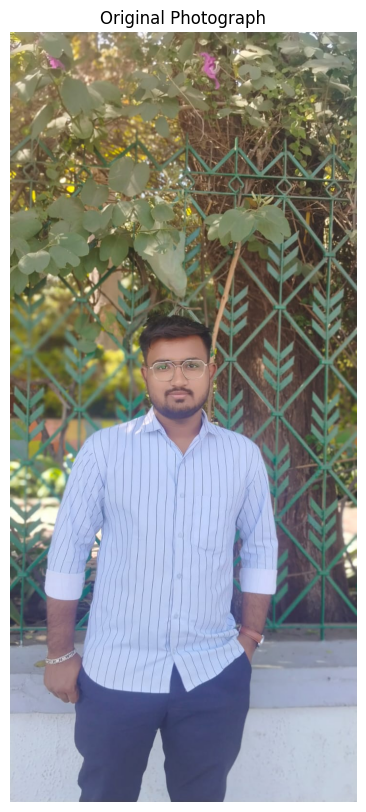

Image loaded successfully!
Image dimensions: (1600, 720, 3)


In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project directory
PROJECT_DIR = Path.cwd()

# Image path
IMAGE_PATH = PROJECT_DIR / "data" / "images" / "original.jpg"

# Load the original photograph
image = cv2.imread(str(IMAGE_PATH))

if image is None:
    print("Image not found!")
    print("Expected path:", IMAGE_PATH.resolve())
else:
    # Convert BGR to RGB
    original = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Display the photograph
    plt.figure(figsize=(7, 10))
    plt.imshow(original)
    plt.title("Original Photograph")
    plt.axis("off")
    plt.show()

    print("Image loaded successfully!")
    print("Image dimensions:", original.shape)

## Task 1A: Image Restoration
1. Add Gaussian noise and salt-and-pepper noise to the photograph. 

In [14]:
from pathlib import Path

# Create the output directory
OUTPUT_DIR = Path.cwd() / "outputs" / "task1_image_restoration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder created:", OUTPUT_DIR.resolve())

Output folder created: D:\CV-Assignment\outputs\task1_image_restoration


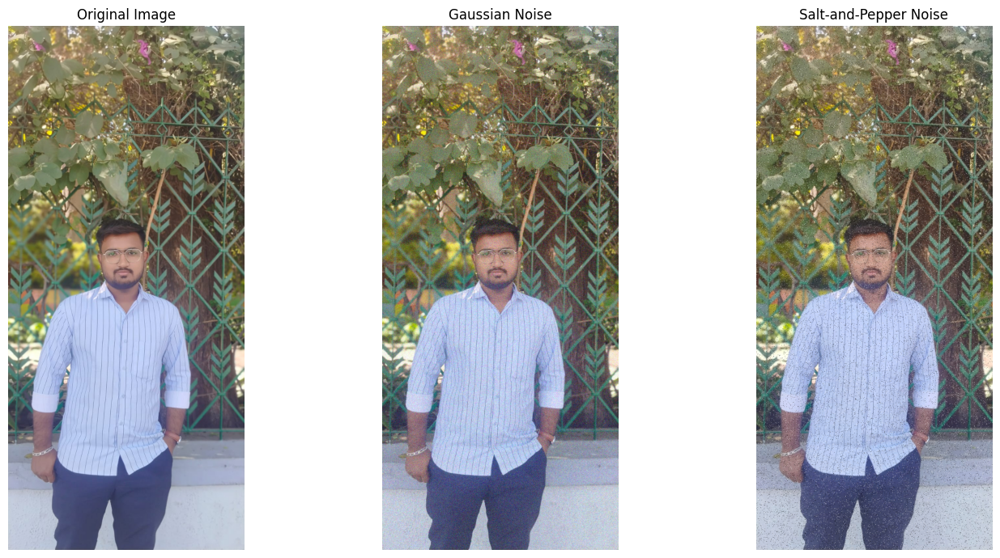

Gaussian noise added successfully.
Salt-and-pepper noise added successfully.
Output images saved in: D:\CV-Assignment\outputs\task1_image_restoration


In [15]:
# Task 1A: Adding Noise to the Original Image

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Set random seed for reproducible results
np.random.seed(42)

# Create output directory
OUTPUT_DIR = Path.cwd() / "outputs" / "task1_image_restoration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Get image dimensions
height, width, channels = original.shape

# -----------------------------------
# 1. Gaussian Noise
# -----------------------------------

gaussian_noise = np.random.normal(
    0, 20, original.shape
)

gaussian_noisy = np.clip(
    original.astype(np.float32) + gaussian_noise,
    0, 255
).astype(np.uint8)

# -----------------------------------
# 2. Salt-and-Pepper Noise
# -----------------------------------

salt_pepper_noisy = original.copy()

noise_amount = 0.04
num_pixels = int(noise_amount * height * width)

# Add white pixels (salt)
num_salt = num_pixels // 2

salt_y = np.random.randint(0, height, num_salt)
salt_x = np.random.randint(0, width, num_salt)

salt_pepper_noisy[salt_y, salt_x] = 255

# Add black pixels (pepper)
num_pepper = num_pixels - num_salt

pepper_y = np.random.randint(0, height, num_pepper)
pepper_x = np.random.randint(0, width, num_pepper)

salt_pepper_noisy[pepper_y, pepper_x] = 0

# -----------------------------------
# 3. Display Comparison
# -----------------------------------

plt.figure(figsize=(15, 7))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_noisy)
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(salt_pepper_noisy)
plt.title("Salt-and-Pepper Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

# -----------------------------------
# 4. Save Output Images
# -----------------------------------

plt.imsave(OUTPUT_DIR / "original.png", original)
plt.imsave(OUTPUT_DIR / "gaussian_noise.png", gaussian_noisy)
plt.imsave(OUTPUT_DIR / "salt_pepper_noise.png", salt_pepper_noisy)

print("Gaussian noise added successfully.")
print("Salt-and-pepper noise added successfully.")
print("Output images saved in:", OUTPUT_DIR.resolve())

2. Apply median filtering and Gaussian filtering to restore the noisy images.

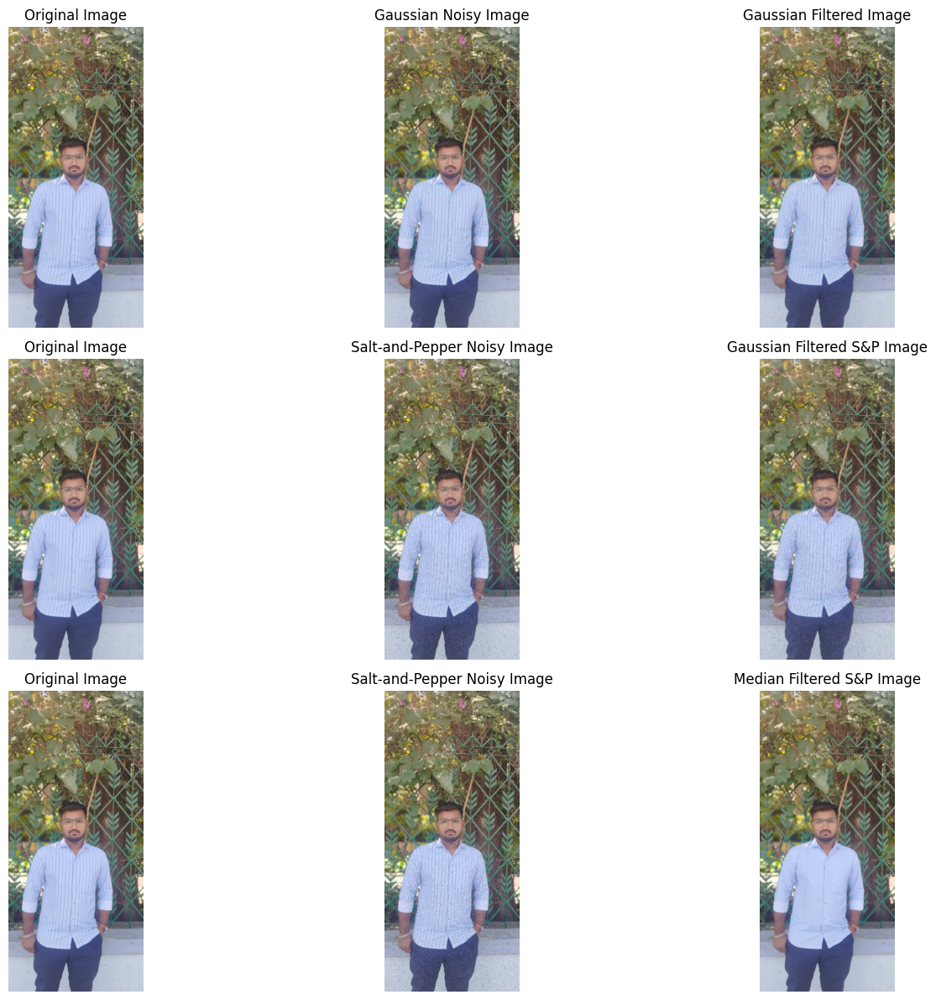

Gaussian filtering completed.
Median filtering completed.
All restored images saved successfully.
Output folder: D:\CV-Assignment\outputs\task1_image_restoration


In [16]:
# Task 1A: Image Restoration Using Median and Gaussian Filters

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Create output directory
OUTPUT_DIR = Path.cwd() / "outputs" / "task1_image_restoration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------
# 1. Gaussian Filtering
# ------------------------------------------

# Restore Gaussian noisy image
gaussian_restored = cv2.GaussianBlur(
    gaussian_noisy,
    (5, 5),
    1.0
)

# Restore salt-and-pepper noisy image
gaussian_filtered_sp = cv2.GaussianBlur(
    salt_pepper_noisy,
    (5, 5),
    1.0
)

# ------------------------------------------
# 2. Median Filtering
# ------------------------------------------

# Restore Gaussian noisy image
median_restored = cv2.medianBlur(
    gaussian_noisy,
    5
)

# Restore salt-and-pepper noisy image
median_filtered_sp = cv2.medianBlur(
    salt_pepper_noisy,
    5
)

# ------------------------------------------
# 3. Display the Results
# ------------------------------------------

plt.figure(figsize=(16, 12))

plt.subplot(3, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(3, 3, 2)
plt.imshow(gaussian_noisy)
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(3, 3, 3)
plt.imshow(gaussian_restored)
plt.title("Gaussian Filtered Image")
plt.axis("off")

plt.subplot(3, 3, 4)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(3, 3, 5)
plt.imshow(salt_pepper_noisy)
plt.title("Salt-and-Pepper Noisy Image")
plt.axis("off")

plt.subplot(3, 3, 6)
plt.imshow(gaussian_filtered_sp)
plt.title("Gaussian Filtered S&P Image")
plt.axis("off")

plt.subplot(3, 3, 7)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(3, 3, 8)
plt.imshow(salt_pepper_noisy)
plt.title("Salt-and-Pepper Noisy Image")
plt.axis("off")

plt.subplot(3, 3, 9)
plt.imshow(median_filtered_sp)
plt.title("Median Filtered S&P Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------
# 4. Save Restored Images
# ------------------------------------------

plt.imsave(OUTPUT_DIR / "gaussian_filtered.png", gaussian_restored)
plt.imsave(OUTPUT_DIR / "median_filtered_gaussian.png", median_restored)
plt.imsave(OUTPUT_DIR / "gaussian_filtered_salt_pepper.png", gaussian_filtered_sp)
plt.imsave(OUTPUT_DIR / "median_filtered_salt_pepper.png", median_filtered_sp)

print("Gaussian filtering completed.")
print("Median filtering completed.")
print("All restored images saved successfully.")
print("Output folder:", OUTPUT_DIR.resolve())

4. Calculate PSNR and SSIM where applicable. 


In [17]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import pandas as pd

# Images to compare with the original
images = {
    "Gaussian Noisy": gaussian_noisy,
    "Gaussian Filtered": gaussian_restored,
    "Median Filtered (Gaussian Noise)": median_restored,
    "Salt-and-Pepper Noisy": salt_pepper_noisy,
    "Gaussian Filtered (Salt-and-Pepper)": gaussian_filtered_sp,
    "Median Filtered (Salt-and-Pepper)": median_filtered_sp
}

results = []

for name, img in images.items():
    psnr = peak_signal_noise_ratio(original, img, data_range=255)

    ssim = structural_similarity(
        original,
        img,
        channel_axis=-1,
        data_range=255
    )

    results.append({
        "Image": name,
        "PSNR (dB)": round(psnr, 2),
        "SSIM": round(ssim, 4)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

# Save results
comparison_df.to_csv(
    OUTPUT_DIR / "restoration_metrics.csv",
    index=False
)

print("PSNR and SSIM calculated and saved successfully.")

,Image,PSNR (dB),SSIM
0,Gaussian Noisy,22.20,0.3795
1,Gaussian Filtered,30.32,0.7857
2,Median Filtered (Gaussian Noise),28.85,0.7551
3,Salt-and-Pepper Noisy,19.37,0.4105
4,Gaussian Filtered (Salt-and-Pepper),28.35,0.7172
5,Median Filtered (Salt-and-Pepper),30.53,0.8790


PSNR and SSIM calculated and saved successfully.


### B. Morphological Processing and Segmentation 

5. Convert a suitable image into a binary image using thresholding. 


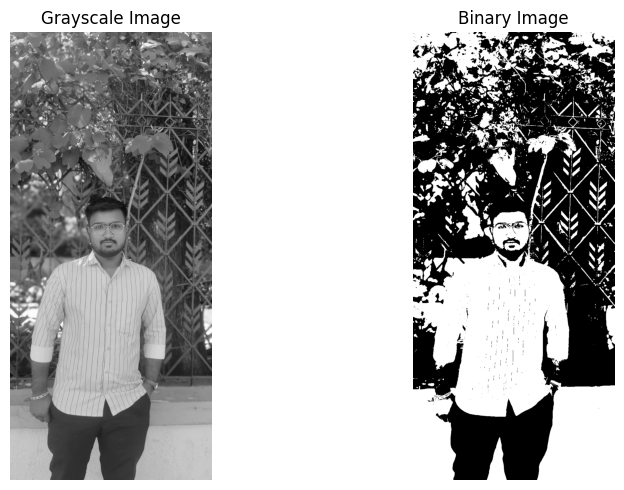

In [18]:
# Convert RGB image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Apply binary thresholding
_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# Display results
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
plt.imsave(OUTPUT_DIR / "binary_image.png", binary, cmap="gray")

6. Apply erosion, dilation, opening and closing. 


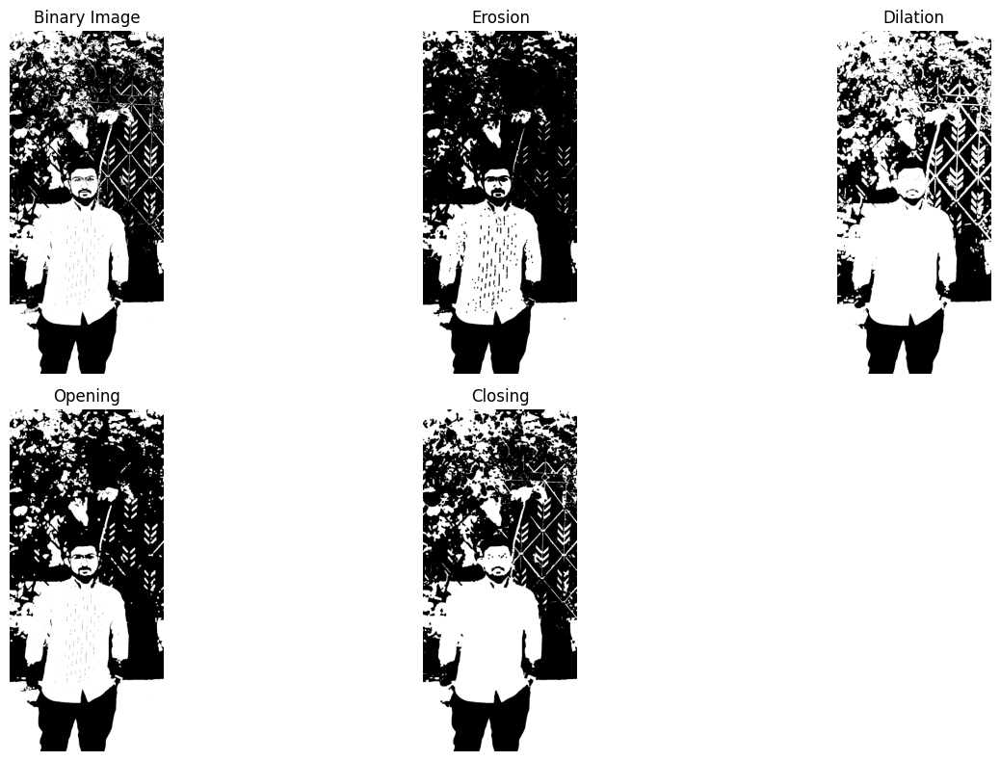

Morphological operations completed.


In [19]:
# Create a morphological kernel
kernel = np.ones((5, 5), np.uint8)

# Apply morphological operations
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# Display results
images = [
    (binary, "Binary Image"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing")
]

plt.figure(figsize=(14, 8))

for i, (img, title) in enumerate(images, 1):
    plt.subplot(2, 3, i)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Save outputs
for img, title in images[1:]:
    filename = title.lower() + ".png"
    cv2.imwrite(str(OUTPUT_DIR / filename), img)

print("Morphological operations completed.")

7. Apply Canny edge detection. 


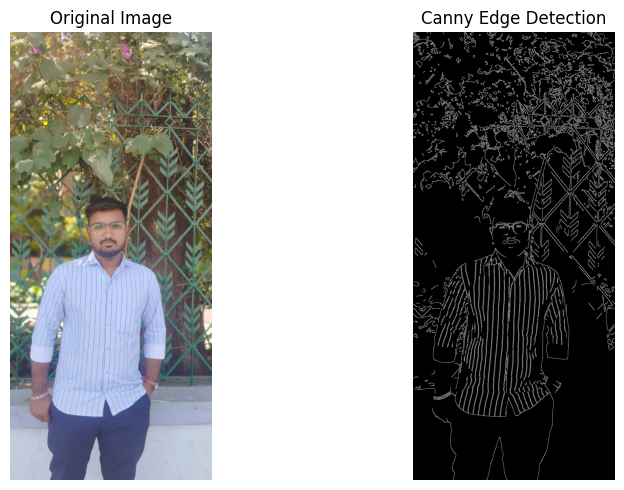

Canny edge detection completed.


In [20]:
# Apply Canny edge detection
edges = cv2.Canny(gray, 100, 200)

# Display results
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
cv2.imwrite(str(OUTPUT_DIR / "canny_edges.png"), edges)

print("Canny edge detection completed.")

8. Perform watershed segmentation on a suitable image containing multiple or touching objects. 


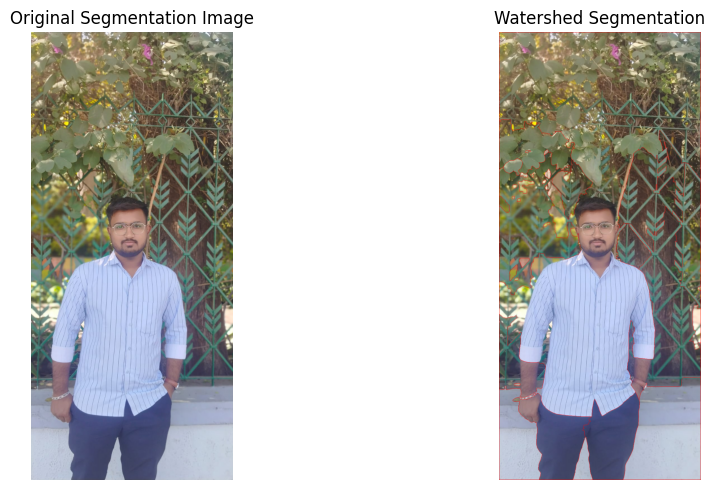

Watershed segmentation completed.


In [23]:
# Load a suitable image containing multiple objects

SEGMENTATION_PATH = Path.cwd() / "data" / "images" / "original.jpg"
seg_image = cv2.imread(str(SEGMENTATION_PATH))

if seg_image is None:
    raise FileNotFoundError(
        f"Please save a suitable image at: {SEGMENTATION_PATH}"
    )

# Convert BGR to RGB for display
seg_rgb = cv2.cvtColor(seg_image, cv2.COLOR_BGR2RGB)

# Convert to grayscale and apply Otsu thresholding
seg_gray = cv2.cvtColor(seg_image, cv2.COLOR_BGR2GRAY)
_, thresh = cv2.threshold(
    seg_gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
opening_ws = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel, iterations=2
)

# Identify background
sure_bg = cv2.dilate(opening_ws, kernel, iterations=3)

# Identify foreground
dist_transform = cv2.distanceTransform(
    opening_ws, cv2.DIST_L2, 5
)

_, sure_fg = cv2.threshold(
    dist_transform,
    0.4 * dist_transform.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Identify uncertain regions
unknown = cv2.subtract(sure_bg, sure_fg)

# Create markers
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
markers = cv2.watershed(seg_image, markers)

# Mark boundaries in red
watershed_result = seg_rgb.copy()
watershed_result[markers == -1] = [255, 0, 0]

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(seg_rgb)
plt.title("Original Segmentation Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(watershed_result)
plt.title("Watershed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
plt.imsave(
    OUTPUT_DIR / "watershed_segmentation.png",
    watershed_result
)

print("Watershed segmentation completed.")

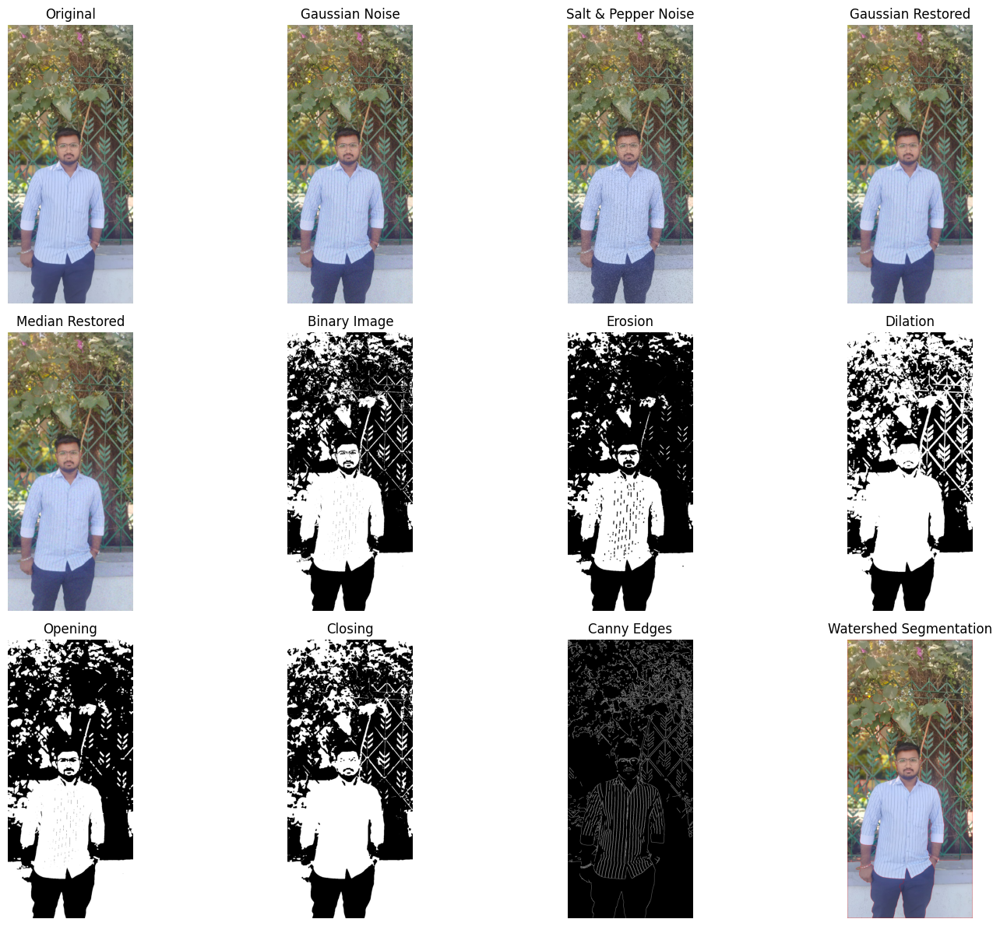

In [24]:
import matplotlib.pyplot as plt

images = [
    ("Original", original),
    ("Gaussian Noise", gaussian_noisy),
    ("Salt & Pepper Noise", salt_pepper_noisy),
    ("Gaussian Restored", gaussian_restored),
    ("Median Restored", median_restored),
    ("Binary Image", binary),
    ("Erosion", erosion),
    ("Dilation", dilation),
    ("Opening", opening),
    ("Closing", closing),
    ("Canny Edges", edges),
    ("Watershed Segmentation", watershed_result)
]

plt.figure(figsize=(16, 12))

for i, (title, img) in enumerate(images):
    plt.subplot(3, 4, i + 1)
    plt.imshow(img, cmap="gray" if img.ndim == 2 else None)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Conclusion

The results show that different image processing techniques are useful for different purposes. Gaussian noise adds smooth random variations, while salt-and-pepper noise creates distinct black and white spots. Gaussian filtering reduces Gaussian noise but slightly blurs image details, whereas median filtering is more effective at removing salt-and-pepper noise while preserving edges.

Binary thresholding converts the grayscale image into black and white regions. Erosion reduces white regions, dilation expands them, opening removes small white noise, and closing fills small gaps. Canny edge detection highlights the boundaries and outlines of objects. Watershed segmentation identifies regions in the image, although it does not clearly separate objects in this particular image.

Overall, **median filtering is effective for salt-and-pepper noise, Gaussian filtering is suitable for Gaussian noise, and Canny is useful for edge detection**. The effectiveness of thresholding, morphological operations, and watershed segmentation depends on the image and the selected parameters.


# Task 2: Feature Extraction and Image Matching


1. Extract and visualize Histogram of Oriented Gradients (HOG) features. 


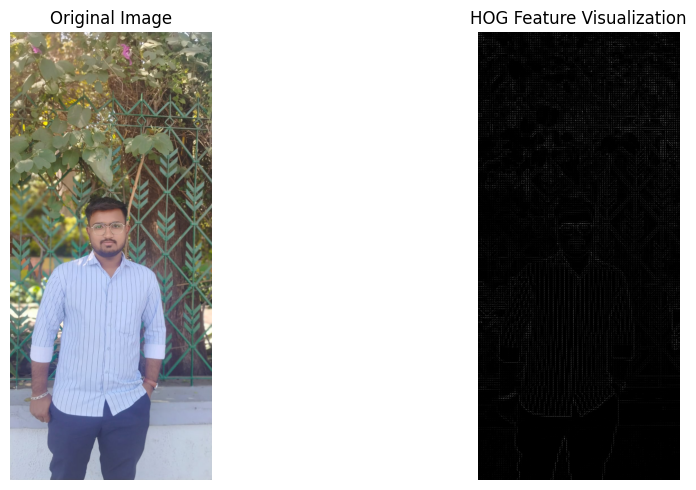

HOG feature vector shape: (637596,)


In [25]:
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog

# Convert image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Extract HOG features
hog_features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

# Display original and HOG images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Feature Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()

print("HOG feature vector shape:", hog_features.shape)

2. Detect SIFT keypoints and calculate descriptors. 

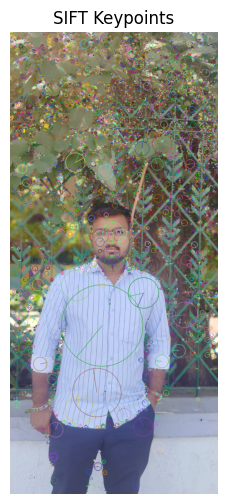

Number of keypoints detected: 6198
Descriptor shape: (6198, 128)


In [26]:
import cv2
import matplotlib.pyplot as plt

# Convert the original image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and calculate descriptors
keypoints, descriptors = sift.detectAndCompute(gray, None)

# Draw keypoints on the original image
sift_image = cv2.drawKeypoints(
    original,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display the image with keypoints
plt.figure(figsize=(10, 6))
plt.imshow(sift_image)
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()

# Display results
print("Number of keypoints detected:", len(keypoints))
print("Descriptor shape:", descriptors.shape if descriptors is not None else None)

3. Match the SIFT features between the two images. 

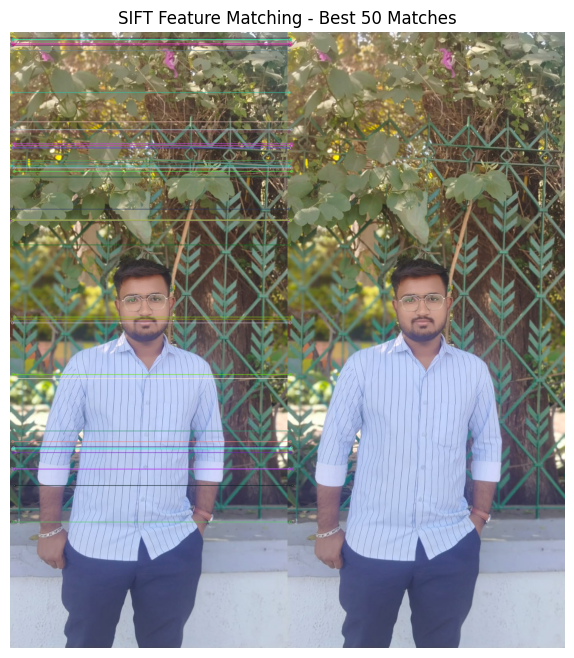

Keypoints in Image 1: 6198
Keypoints in Image 2: 6198
Good matches displayed: 50


In [29]:
import cv2
import matplotlib.pyplot as plt

# Load the two images
img1 = original.copy()
img2_color = cv2.imread("data/images/second.jpg")

if img2_color is None:
    raise FileNotFoundError("Check the path to second.jpg")

gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(img2_color, cv2.COLOR_BGR2GRAY)

# Detect SIFT features
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

# Match descriptors using KNN
bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Apply a stricter Lowe's ratio test
good_matches = [
    m for m, n in matches
    if m.distance < 0.6 * n.distance
]

# Keep only the 50 best matches
good_matches = sorted(good_matches, key=lambda x: x.distance)[:50]

# Draw matches
matched_image = cv2.drawMatches(
    img1, kp1,
    cv2.cvtColor(img2_color, cv2.COLOR_BGR2RGB), kp2,
    good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display results
plt.figure(figsize=(16, 8))
plt.imshow(matched_image)
plt.title("SIFT Feature Matching - Best 50 Matches")
plt.axis("off")
plt.show()

print("Keypoints in Image 1:", len(kp1))
print("Keypoints in Image 2:", len(kp2))
print("Good matches displayed:", len(good_matches))
matched_image_task3 = matched_image.copy()

4. Repeat the matching experiment after rotating or resizing one image. 

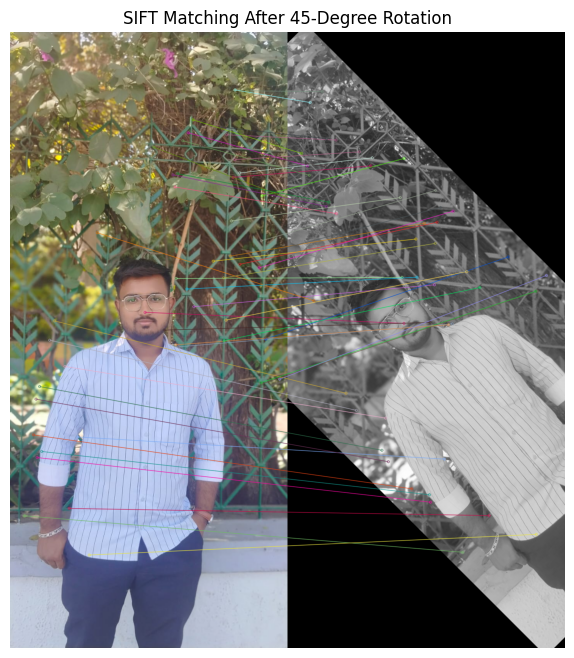

Original keypoints: 6198
Rotated keypoints: 3753
Good matches: 50


In [30]:
import cv2
import matplotlib.pyplot as plt

# Original image
img1 = original.copy()
gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)

# Rotate the image by 45 degrees
h, w = gray1.shape
center = (w // 2, h // 2)

matrix = cv2.getRotationMatrix2D(center, 45, 1.0)
rotated = cv2.warpAffine(gray1, matrix, (w, h))

# Detect SIFT features
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(rotated, None)

# Match features
bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Apply Lowe's ratio test
good_matches = [
    m for m, n in matches
    if m.distance < 0.7 * n.distance
]

# Display the 50 best matches
good_matches = sorted(good_matches, key=lambda x: x.distance)[:50]

matched_image = cv2.drawMatches(
    img1, kp1,
    cv2.cvtColor(rotated, cv2.COLOR_GRAY2RGB), kp2,
    good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display results
plt.figure(figsize=(16, 8))
plt.imshow(matched_image)
plt.title("SIFT Matching After 45-Degree Rotation")
plt.axis("off")
plt.show()

print("Original keypoints:", len(kp1))
print("Rotated keypoints:", len(kp2))
print("Good matches:", len(good_matches))
matched_image_task4 = matched_image.copy()

5. Display and compare the matching results. 

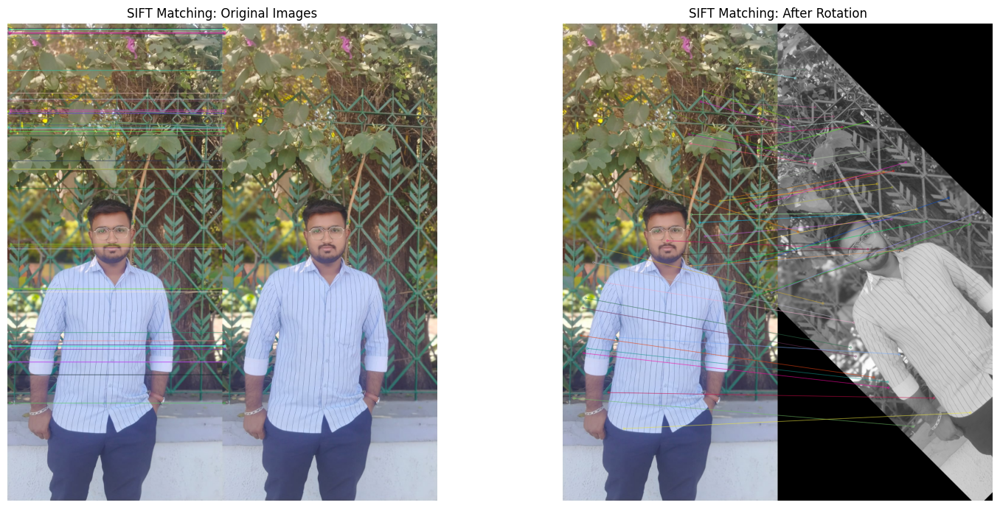

In [31]:
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(matched_image_task3)
plt.title("SIFT Matching: Original Images")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(matched_image_task4)
plt.title("SIFT Matching: After Rotation")
plt.axis("off")

plt.tight_layout()
plt.show()

# Task 3: Object Recognition Using Viola–Jones and YOLO

1. Apply a pretrained Haar cascade classifier to detect faces or another supported object. 


In [41]:
import urllib.request

url = "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml"

urllib.request.urlretrieve(
    url,
    "haarcascade_frontalface_default.xml"
)

print("Haar cascade downloaded successfully!")

Haar cascade downloaded successfully!


In [42]:
import cv2

face_cascade = cv2.CascadeClassifier(
    "haarcascade_frontalface_default.xml"
)

print("Classifier loaded:", not face_cascade.empty())

Classifier loaded: True


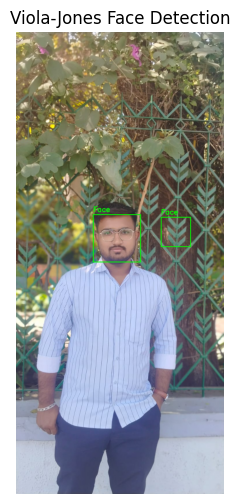

Number of faces detected: 2


In [34]:
import cv2
import matplotlib.pyplot as plt

# 1. Load the photograph
image = cv2.imread("data/images/original.jpg")

if image is None:
    raise FileNotFoundError("Check the path to original.jpg")

# 2. Convert the image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# 3. Load the pretrained Haar cascade classifier
face_cascade = cv2.CascadeClassifier(
    "haarcascade_frontalface_default.xml"
)

if face_cascade.empty():
    raise ValueError("Haar cascade classifier could not be loaded.")

# 4. Detect faces
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# 5. Draw bounding boxes around detected faces
result = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        result,
        "Face",
        (x, y - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

# 6. Display the result
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Viola-Jones Face Detection")
plt.axis("off")
plt.show()

print("Number of faces detected:", len(faces))

2. Apply a pretrained YOLO model to detect supported objects. 


Pretrained YOLO model loaded successfully!

Object detection completed!

Detected Objects:
Object: person, Confidence: 92.15%

YOLO Object Detection Result:


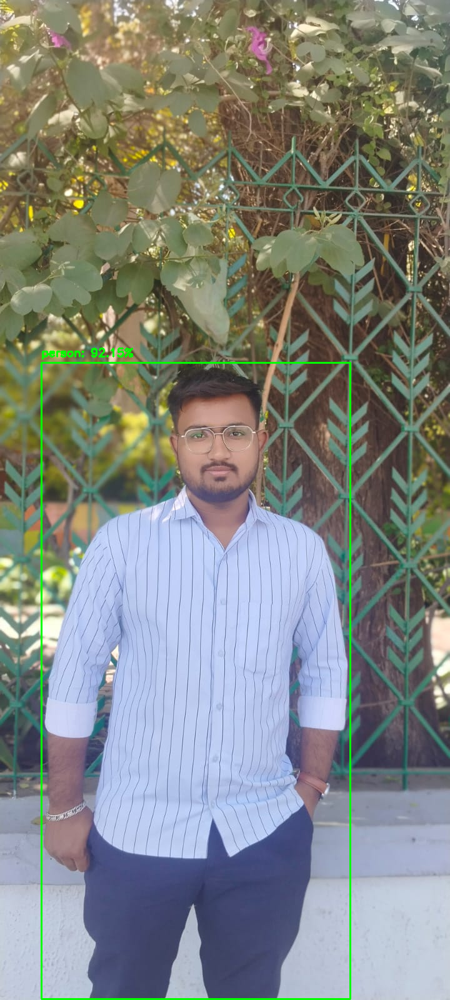

In [35]:
# Task 3.2: Object Detection Using a Pretrained YOLO Model

import cv2
from ultralytics import YOLO
from PIL import Image
from IPython.display import display

# 1. Load the pretrained YOLO model
model = YOLO("yolov8n.pt")
print("Pretrained YOLO model loaded successfully!")

# 2. Load the input photograph
image = cv2.imread("data/images/original.jpg")

if image is None:
    raise FileNotFoundError("Check the path to original.jpeg")

# 3. Perform object detection
results = model.predict(
    source=image,
    imgsz=320,
    device="cpu",
    verbose=False
)

print("\nObject detection completed!")

# 4. Create a copy of the image
result_image = image.copy()

# 5. Draw bounding boxes and labels
print("\nDetected Objects:")

if len(results[0].boxes) == 0:
    print("No objects detected.")
else:
    for box in results[0].boxes:
        # Get bounding box coordinates
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        # Get class name and confidence score
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        object_name = model.names[class_id]

        # Draw bounding box
        cv2.rectangle(
            result_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        # Add object label and confidence score
        label = f"{object_name}: {confidence:.2%}"

        cv2.putText(
            result_image,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

        print(f"Object: {object_name}, Confidence: {confidence:.2%}")

# 6. Convert the image from BGR to RGB
result_image_rgb = cv2.cvtColor(
    result_image,
    cv2.COLOR_BGR2RGB
)

# 7. Display the final result using PIL
print("\nYOLO Object Detection Result:")
display(Image.fromarray(result_image_rgb))

3. Display bounding boxes, class labels and confidence scores where applicable. 

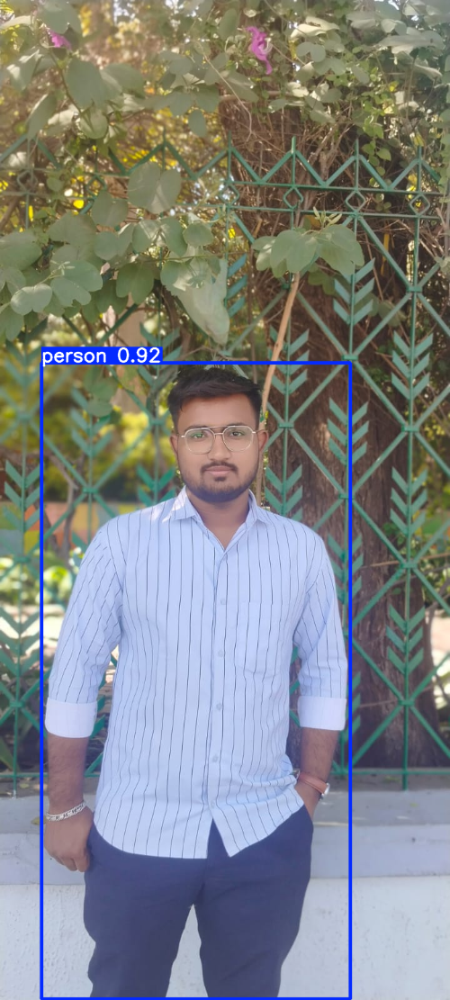

In [36]:
# Task 3.3: Display bounding boxes, class labels, and confidence scores

from PIL import Image
from IPython.display import display
import cv2

# YOLO has already detected the objects in Task 3.2
result_image = results[0].plot()

# Convert BGR to RGB
result_image = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

# Resize for display
height, width = result_image.shape[:2]
new_width = 500
new_height = int(height * new_width / width)

result_image = cv2.resize(result_image, (new_width, new_height))

# Display the annotated image
display(Image.fromarray(result_image))

4. Compare the detection results. 

Viola-Jones: Face Detection
Number of faces detected: 2


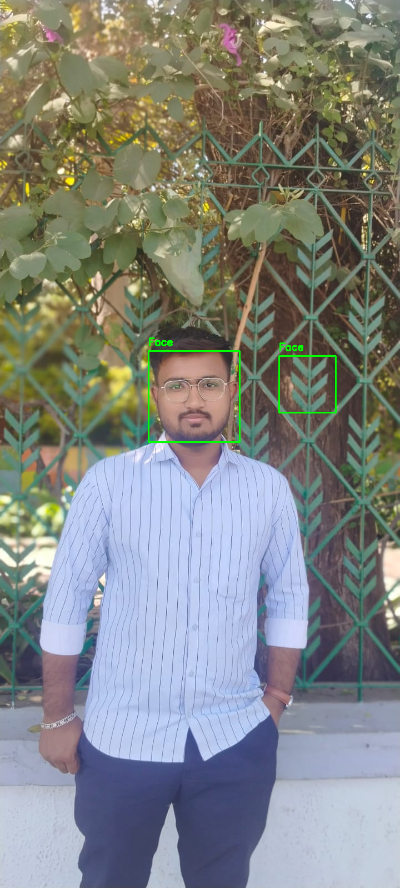


YOLO: Object Detection
Number of objects detected: 1
person: 92.15%


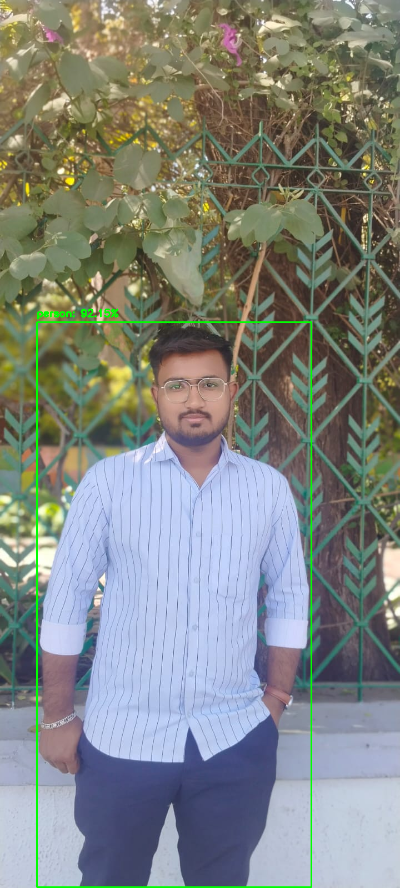

In [37]:
import cv2
from ultralytics import YOLO
from PIL import Image
from IPython.display import display

# Load the original image
image = cv2.imread("data/images/original.jpg")

if image is None:
    raise FileNotFoundError("Check the path to original.jpeg")

# ==========================================
# 1. Viola-Jones Face Detection
# ==========================================

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

face_cascade = cv2.CascadeClassifier(
    "haarcascade_frontalface_default.xml"
)

if face_cascade.empty():
    raise ValueError("Haar cascade XML file could not be loaded.")

faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

haar_image = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        haar_image, (x, y), (x + w, y + h), (0, 255, 0), 2
    )
    cv2.putText(
        haar_image, "Face", (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2
    )

# ==========================================
# 2. YOLO Object Detection
# ==========================================

model = YOLO("yolov8n.pt")

results = model.predict(
    source=image,
    imgsz=320,
    device="cpu",
    verbose=False
)

yolo_image = image.copy()

for box in results[0].boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    label = f"{model.names[class_id]}: {confidence:.2%}"

    cv2.rectangle(
        yolo_image, (x1, y1), (x2, y2), (0, 255, 0), 2
    )
    cv2.putText(
        yolo_image, label, (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2
    )

# ==========================================
# 3. Resize and Display Both Results
# ==========================================

def resize_image(img, width=400):
    height, original_width = img.shape[:2]
    new_height = int(height * width / original_width)
    return cv2.resize(img, (width, new_height))

print("Viola-Jones: Face Detection")
print("Number of faces detected:", len(faces))
display(Image.fromarray(
    cv2.cvtColor(resize_image(haar_image), cv2.COLOR_BGR2RGB)
))

print("\nYOLO: Object Detection")
print("Number of objects detected:", len(results[0].boxes))

for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    print(f"{model.names[class_id]}: {confidence:.2%}")

display(Image.fromarray(
    cv2.cvtColor(resize_image(yolo_image), cv2.COLOR_BGR2RGB)
))

5. Identify at least one case in which a detector misses an object or produces an incorrect detection, 
if encountered.

In [38]:
# Task 3.5: Inspect YOLO Detection Results

print("YOLO Detection Analysis")

if len(results[0].boxes) == 0:
    print("No objects detected.")
else:
    for i, box in enumerate(results[0].boxes, start=1):
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        print(f"\nDetection {i}")
        print("Object:", model.names[class_id])
        print(f"Confidence: {confidence:.2%}")
        print("Bounding box:", (x1, y1, x2, y2))

YOLO Detection Analysis

Detection 1
Object: person
Confidence: 92.15%
Bounding box: (66, 580, 560, 1598)


### Conclusion

In this experiment, pretrained Viola–Jones and YOLO models were applied to an image for face and object detection. Viola–Jones used a Haar Cascade classifier to detect frontal faces, while YOLO detected multiple supported object classes and provided bounding boxes, class labels, and confidence scores.

The results demonstrated that Viola–Jones is a lightweight approach suitable for face detection, whereas YOLO is more versatile for detecting different types of objects. Both methods have limitations and may miss objects or produce incorrect detections depending on image quality, lighting, object orientation, and occlusion.

Overall, this experiment helped demonstrate the differences between traditional computer vision techniques and deep-learning-based object detection methods.

# Task 4: Video Motion Estimation


1. Extract consecutive frames from the video. 

Total frames: 1725
FPS: 60.01157324639612
Duration (seconds): 28.74


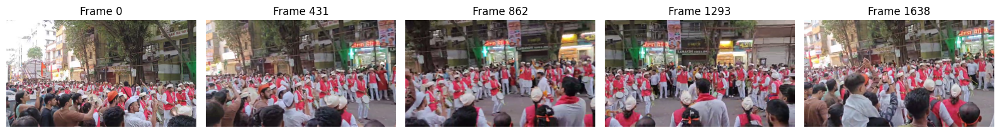

Frames extracted: 5


In [48]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Open the video
video_path = Path.cwd() / "data" / "videos" / "v1.mp4"

if not video_path.is_file():
    raise FileNotFoundError(f"Video file not found: {video_path.resolve()}")

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise OSError(f"OpenCV could not open the video: {video_path.resolve()}")

# Get video information
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)

print("Total frames:", total_frames)
print("FPS:", fps)
print("Duration (seconds):", round(total_frames / fps, 2) if fps > 0 else "Unknown")

# Select five frames at different intervals
frame_numbers = [
    int(total_frames * fraction)
    for fraction in [0.0, 0.25, 0.50, 0.75, 0.95]
]

frames = []

for frame_number in frame_numbers:
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append((frame_number, frame))

cap.release()

# Display selected frames
if frames:
    fig, axes = plt.subplots(1, len(frames), figsize=(16, 5))

    if len(frames) == 1:
        axes = [axes]

    for ax, (number, frame) in zip(axes, frames):
        ax.imshow(frame)
        ax.set_title(f"Frame {number}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("Frames extracted:", len(frames))

2. Apply frame differencing to identify moving regions. 

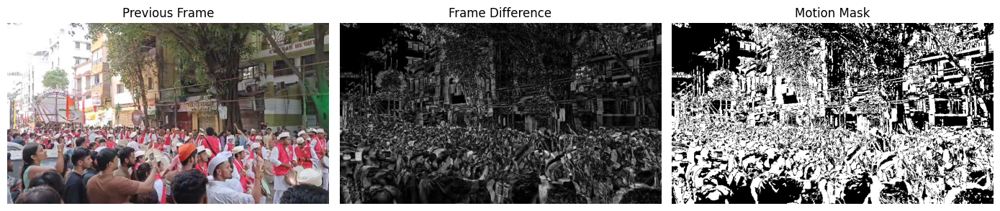

In [49]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

video_path = Path.cwd() / "data" / "videos" / "v1.mp4"
cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise FileNotFoundError("Unable to open video.")

# Read the first frame
ret, previous_frame = cap.read()

if not ret:
    cap.release()
    raise ValueError("Unable to read the first frame.")

previous_gray = cv2.cvtColor(previous_frame, cv2.COLOR_BGR2GRAY)

# Skip some frames to make motion easier to observe
cap.set(cv2.CAP_PROP_POS_FRAMES, 10)
ret, current_frame = cap.read()

cap.release()

if not ret:
    raise ValueError("The video does not contain enough frames.")

current_gray = cv2.cvtColor(current_frame, cv2.COLOR_BGR2GRAY)

# Calculate the absolute difference
frame_difference = cv2.absdiff(previous_gray, current_gray)

# Apply thresholding
_, difference_mask = cv2.threshold(
    frame_difference, 25, 255, cv2.THRESH_BINARY
)

# Display results
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(previous_frame, cv2.COLOR_BGR2RGB))
plt.title("Previous Frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(frame_difference, cmap="gray")
plt.title("Frame Difference")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(difference_mask, cmap="gray")
plt.title("Motion Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

3. Apply Gaussian Mixture Model (GMM)-based background subtraction. 

Total frames processed: 1725


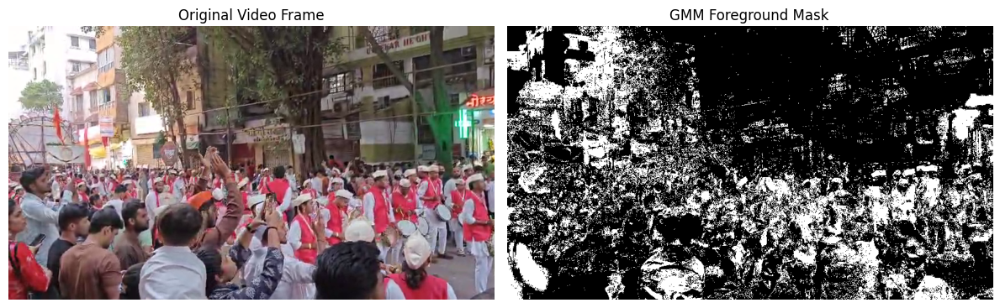

In [50]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Step 1: Locate the video
video_path = Path("data/videos/v1.mp4")

# Check whether the file exists
if not video_path.exists():
    raise FileNotFoundError(
        f"Video not found at: {video_path.resolve()}\n"
        "2.Write your First C++ Program (2).mp4"
    )

# Step 2: Open the video
cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise ValueError("Unable to open the video file.")

# Step 3: Create the GMM background subtractor
back_sub = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=40,
    detectShadows=False
)

# Step 4: Process the video frames
frame_count = 0
frame = None
foreground_mask = None

while True:
    ret, current_frame = cap.read()

    if not ret:
        break

    frame = current_frame
    foreground_mask = back_sub.apply(current_frame)
    frame_count += 1

cap.release()

# Step 5: Check whether frames were processed
if frame_count == 0:
    raise ValueError(
        "The video opened, but no frames were read. "
        "Check whether V1.mp4 is a valid video."
    )

print("Total frames processed:", frame_count)

# Step 6: Convert the frame for display
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Step 7: Display the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(frame_rgb)
plt.title("Original Video Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(foreground_mask, cmap="gray")
plt.title("GMM Foreground Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

4. Apply Lucas–Kanade optical flow to estimate motion between frames. 


Tracked feature points: 100


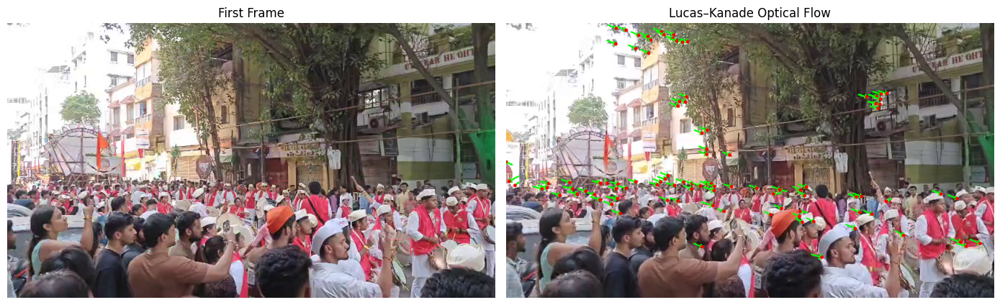

In [51]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Step 1: Open the video
video_path = Path("data/videos/v1.mp4")
cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise FileNotFoundError(
        f"Unable to open video: {video_path.resolve()}"
    )

# Step 2: Read the first frame
ret, old_frame = cap.read()

if not ret:
    cap.release()
    raise ValueError("Unable to read the first frame.")

old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

# Step 3: Read a later frame
cap.set(cv2.CAP_PROP_POS_FRAMES, 10)
ret, new_frame = cap.read()
cap.release()

if not ret:
    raise ValueError(
        "Unable to read frame 10. The video may contain fewer than 11 frames."
    )

new_gray = cv2.cvtColor(new_frame, cv2.COLOR_BGR2GRAY)

# Step 4: Detect feature points
feature_params = dict(
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

p0 = cv2.goodFeaturesToTrack(
    old_gray, mask=None, **feature_params
)

# Step 5: Estimate optical flow
motion_image = new_frame.copy()

if p0 is not None:
    lk_params = dict(
        winSize=(15, 15),
        maxLevel=2,
        criteria=(
            cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
            10,
            0.03
        )
    )

    p1, status, error = cv2.calcOpticalFlowPyrLK(
        old_gray, new_gray, p0, None, **lk_params
    )

    # Step 6: Draw motion vectors
    if p1 is not None and status is not None:
        good_old = p0[status.ravel() == 1]
        good_new = p1[status.ravel() == 1]

        for old, new in zip(good_old, good_new):
            x1, y1 = old.ravel().astype(int)
            x2, y2 = new.ravel().astype(int)

            cv2.arrowedLine(
                motion_image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2,
                tipLength=0.3
            )

            cv2.circle(
                motion_image, (x2, y2), 3, (0, 0, 255), -1
            )

        print("Tracked feature points:", len(good_new))
    else:
        print("Optical flow could not track the feature points.")
else:
    print("No suitable feature points detected in the first frame.")

# Step 7: Display the results
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(old_frame, cv2.COLOR_BGR2RGB))
plt.title("First Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(motion_image, cv2.COLOR_BGR2RGB))
plt.title("Lucas–Kanade Optical Flow")
plt.axis("off")

plt.tight_layout()
plt.show()

5. Display the foreground masks and motion vectors. 

Tracked feature points: 100


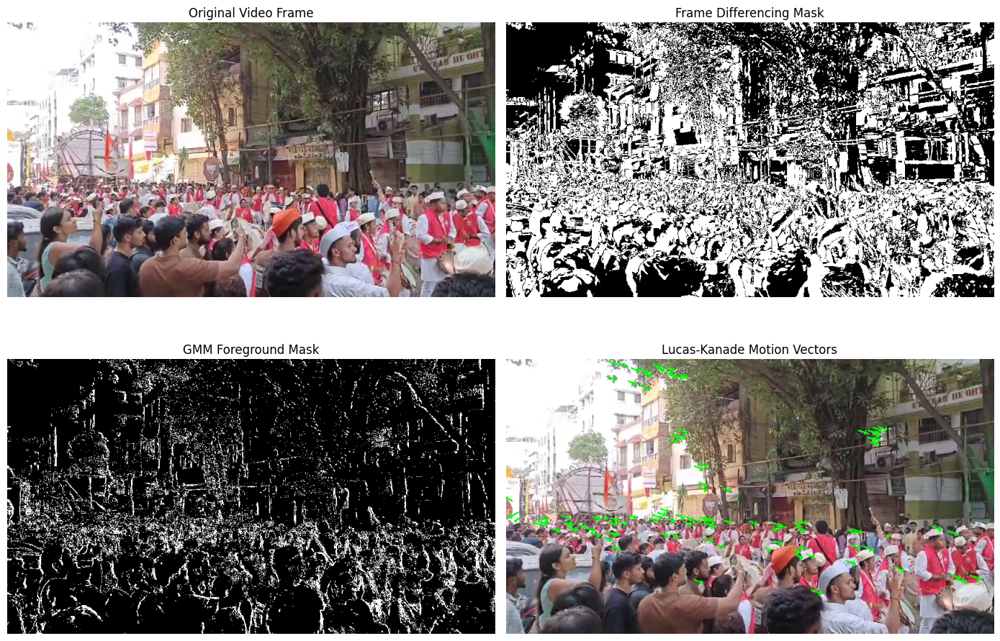

In [52]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Open the video
video_path = Path("data/videos/V1.mp4")
cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise FileNotFoundError(
        f"Cannot open video: {video_path.resolve()}"
    )

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if total_frames < 2:
    cap.release()
    raise ValueError("The video must contain at least two frames.")

# Select two frames
frame_index = min(10, total_frames - 1)

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
ret1, previous_frame = cap.read()

cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
ret2, current_frame = cap.read()

cap.release()

if not ret1 or not ret2:
    raise ValueError("Unable to read the selected video frames.")

# 2. Frame differencing
previous_gray = cv2.cvtColor(previous_frame, cv2.COLOR_BGR2GRAY)
current_gray = cv2.cvtColor(current_frame, cv2.COLOR_BGR2GRAY)

frame_difference = cv2.absdiff(previous_gray, current_gray)

_, difference_mask = cv2.threshold(
    frame_difference, 25, 255, cv2.THRESH_BINARY
)

# 3. GMM background subtraction
cap = cv2.VideoCapture(str(video_path))

back_sub = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=40,
    detectShadows=False
)

foreground_mask = None
frame_number = -1

while True:
    ret, frame = cap.read()

    if not ret:
        break

    frame_number += 1
    mask = back_sub.apply(frame)

    if frame_number == frame_index:
        foreground_mask = mask.copy()
        break

cap.release()

if foreground_mask is None:
    raise ValueError("Unable to generate the GMM foreground mask.")

# 4. Lucas-Kanade optical flow
feature_params = dict(
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

points = cv2.goodFeaturesToTrack(
    previous_gray, mask=None, **feature_params
)

motion_image = current_frame.copy()

if points is not None:
    lk_params = dict(
        winSize=(15, 15),
        maxLevel=2,
        criteria=(
            cv2.TERM_CRITERIA_EPS |
            cv2.TERM_CRITERIA_COUNT,
            10,
            0.03
        )
    )

    new_points, status, error = cv2.calcOpticalFlowPyrLK(
        previous_gray,
        current_gray,
        points,
        None,
        **lk_params
    )

    if new_points is not None and status is not None:
        good_old = points[status.ravel() == 1]
        good_new = new_points[status.ravel() == 1]

        for old, new in zip(good_old, good_new):
            x1, y1 = old.ravel().astype(int)
            x2, y2 = new.ravel().astype(int)

            cv2.arrowedLine(
                motion_image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2,
                tipLength=0.3
            )

        print("Tracked feature points:", len(good_new))
else:
    print("No feature points detected.")

# 5. Display all results
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(current_frame, cv2.COLOR_BGR2RGB))
plt.title("Original Video Frame")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(difference_mask, cmap="gray")
plt.title("Frame Differencing Mask")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(foreground_mask, cmap="gray")
plt.title("GMM Foreground Mask")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(motion_image, cv2.COLOR_BGR2RGB))
plt.title("Lucas-Kanade Motion Vectors")
plt.axis("off")

plt.tight_layout()
plt.show()

6. Compare the results of frame differencing, background subtraction and optical flow. 

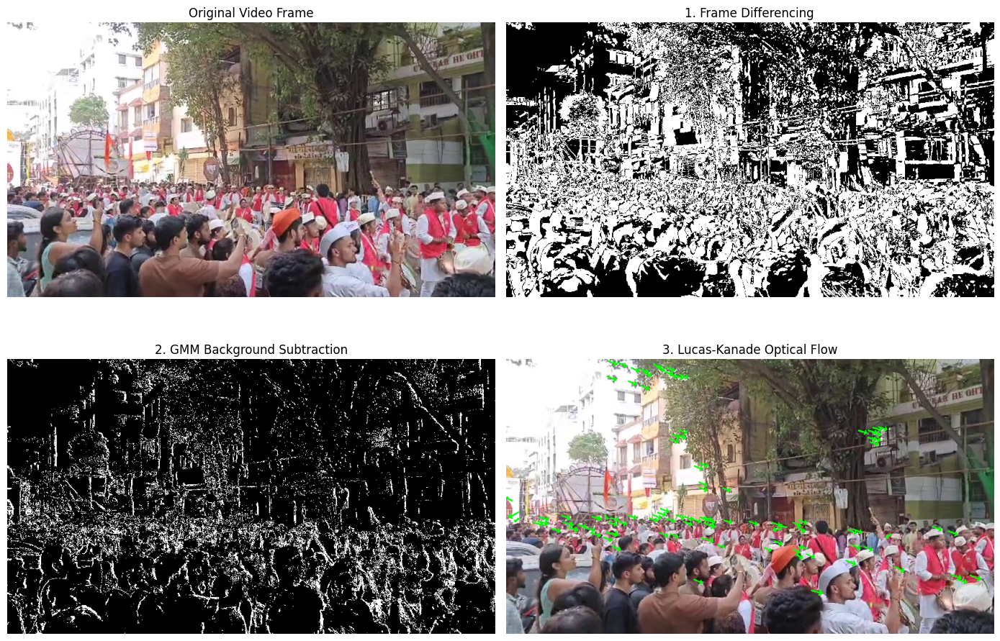

,Method,Output,Advantages,Limitations
0,Frame Differencing,Binary mask showing changes between frames,Simple and fast,Sensitive to noise and lighting changes
1,GMM Background Subtraction,Foreground mask separating objects from the ba...,Learns the background over time,May produce false detections
2,Lucas-Kanade Optical Flow,Motion vectors showing direction and displacement,Estimates motion direction and displacement,Depends on detectable feature points


In [53]:
import cv2
import matplotlib.pyplot as plt
import pandas as pd

# Display outputs from previous tasks
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(current_frame, cv2.COLOR_BGR2RGB))
plt.title("Original Video Frame")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(difference_mask, cmap="gray")
plt.title("1. Frame Differencing")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(foreground_mask, cmap="gray")
plt.title("2. GMM Background Subtraction")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(motion_image, cv2.COLOR_BGR2RGB))
plt.title("3. Lucas-Kanade Optical Flow")
plt.axis("off")

plt.tight_layout()
plt.show()

# Comparison table
comparison = pd.DataFrame({
    "Method": [
        "Frame Differencing",
        "GMM Background Subtraction",
        "Lucas-Kanade Optical Flow"
    ],
    "Output": [
        "Binary mask showing changes between frames",
        "Foreground mask separating objects from the background",
        "Motion vectors showing direction and displacement"
    ],
    "Advantages": [
        "Simple and fast",
        "Learns the background over time",
        "Estimates motion direction and displacement"
    ],
    "Limitations": [
        "Sensitive to noise and lighting changes",
        "May produce false detections",
        "Depends on detectable feature points"
    ]
})

display(comparison)

### Conclusion

In this task, video motion estimation was performed using frame differencing, GMM-based background subtraction, and Lucas–Kanade optical flow. Frame differencing detected changes between consecutive frames, GMM separated foreground objects from the background, and optical flow estimated motion direction and displacement using feature points. The results demonstrated that each method has different advantages and limitations for detecting and analyzing movement in video sequences.


In [54]:
import os
print(os.getcwd())

d:\CV-Assignment
